AROC COMPARISON - TWO DATASETS
Dataset 1: /ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2024_2025_49r1/
Dataset 2: /ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2020_2021/
Output path: ./verification_results/comparison/


LOADING DATASETS

Processing 2024-2025...
----------------------------------------------------------------------
   Found 140 files
   Loaded 9,882,615 matched pairs
   Available types: Rain, Snow, Sleet, Freezing Rain, Freezing Drizzle, Ice Pellets
   Period: 2024-11-12 to 2025-03-31
   ✓ Completed

Processing 2020-2021...
----------------------------------------------------------------------
   Found 177 files
   Loaded 10,868,520 matched pairs
   ⚠️  Warning: 'freezdrizzle' not found in dataset, skipping
   Available types: Rain, Snow, Sleet, Freezing Rain, Ice Pellets
   Period: 2020-10-16 to 2021-04-10
   ✓ Completed

Common precipitation types to compare: Rain, Snow, Sleet, Freezing Rain, Ice Pellets

CREATING COMPARISON PLOTS

1.

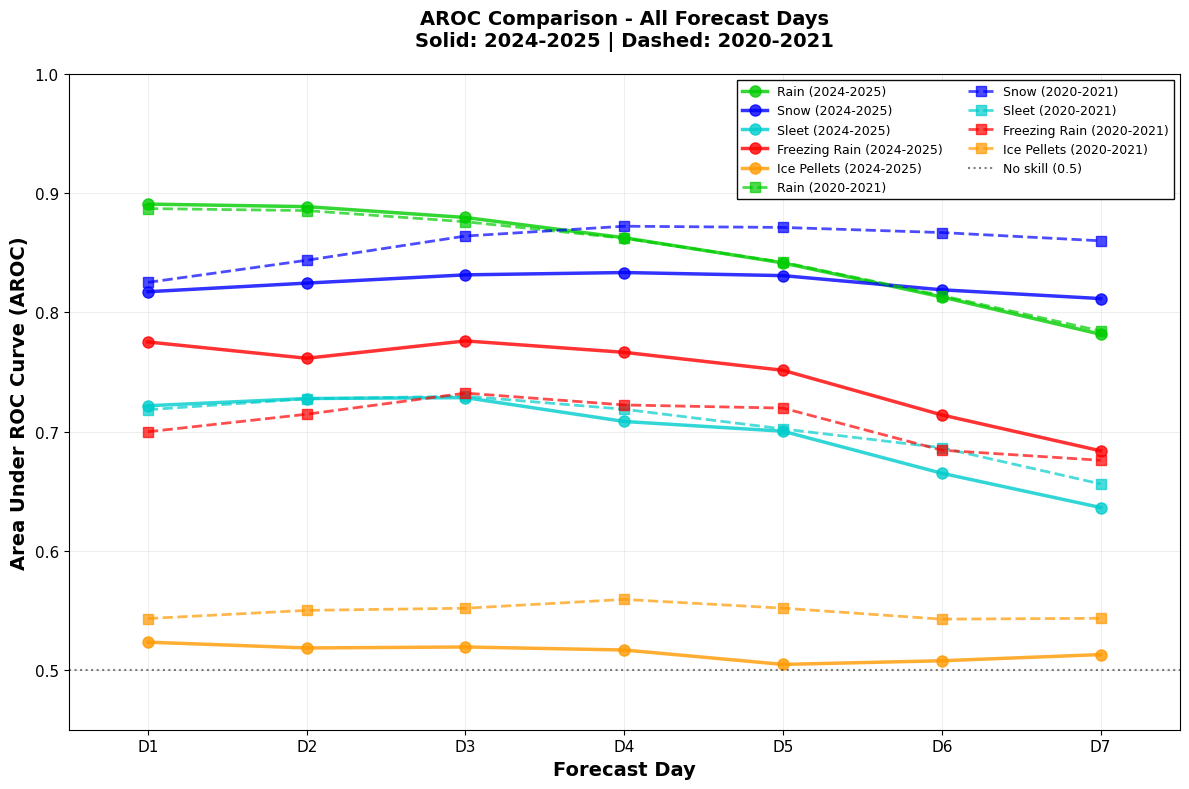

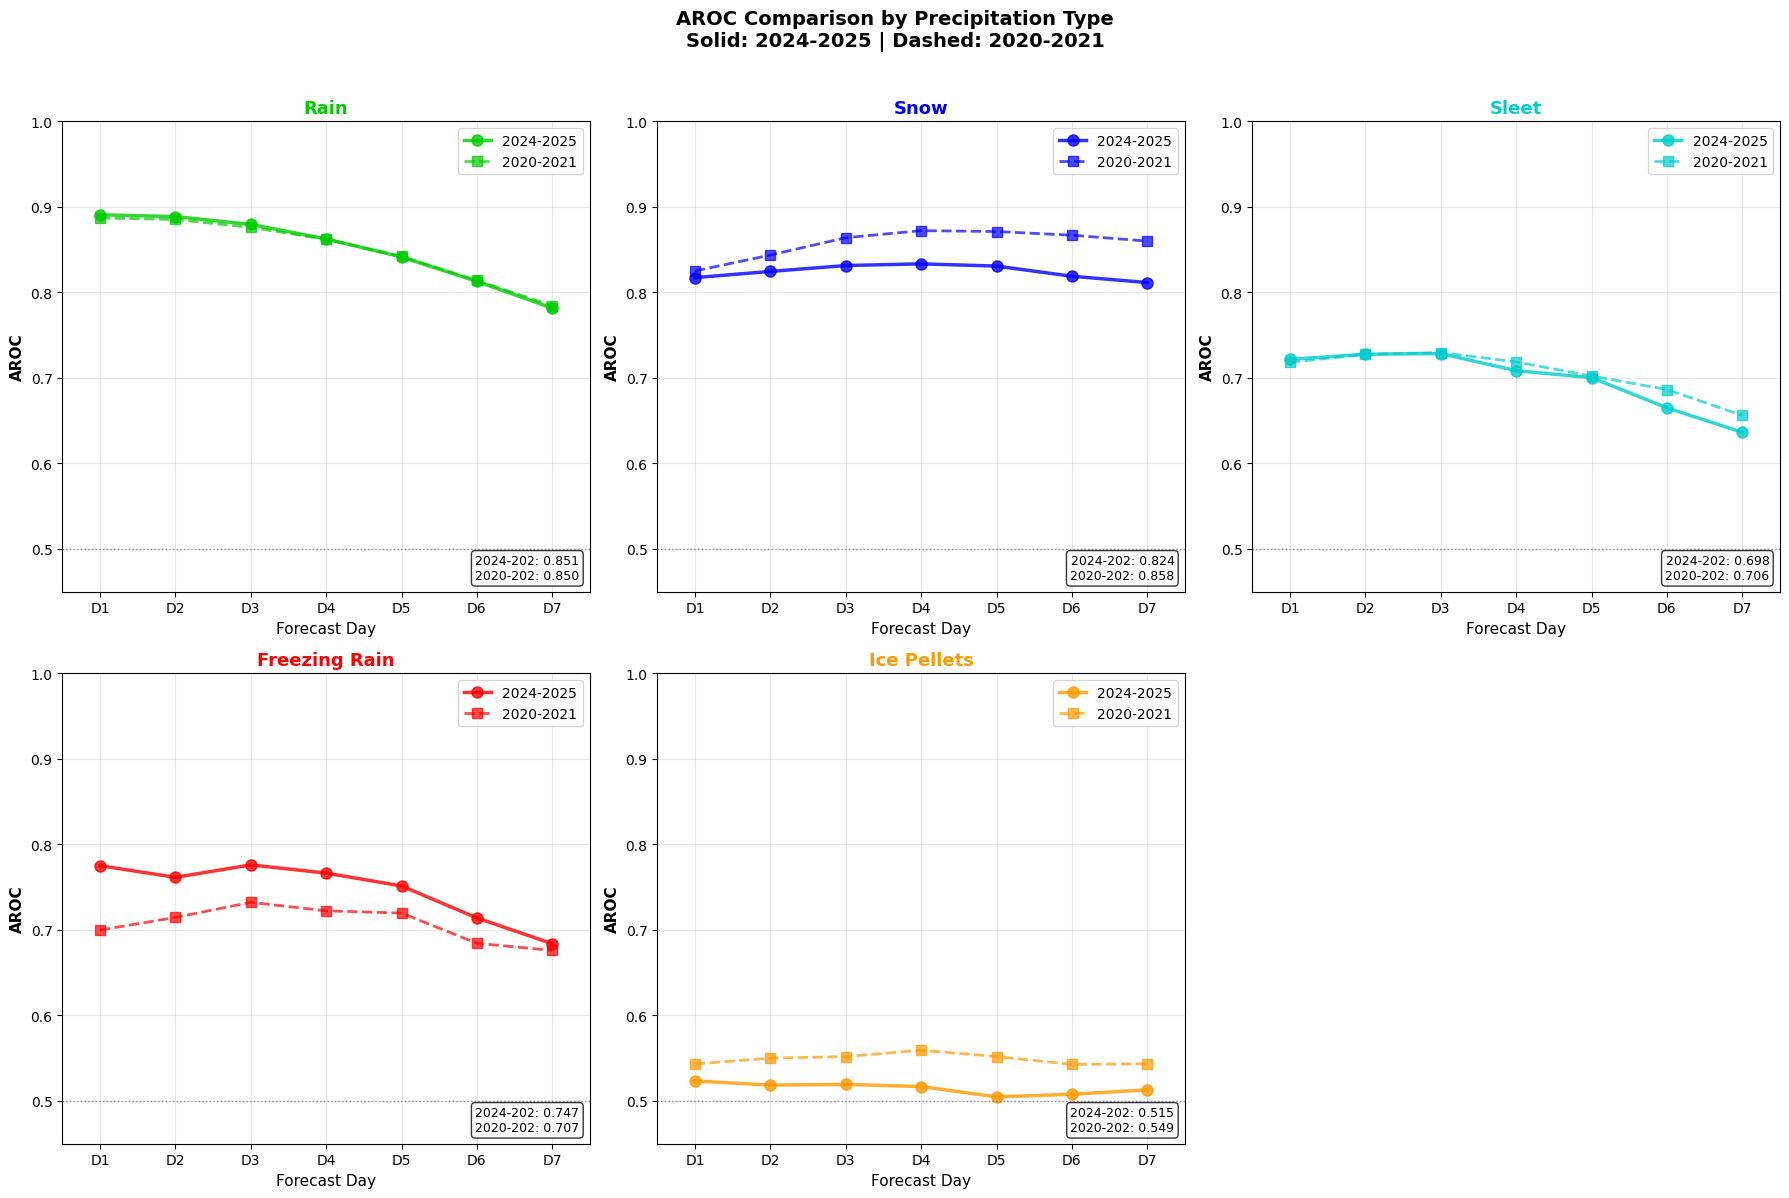

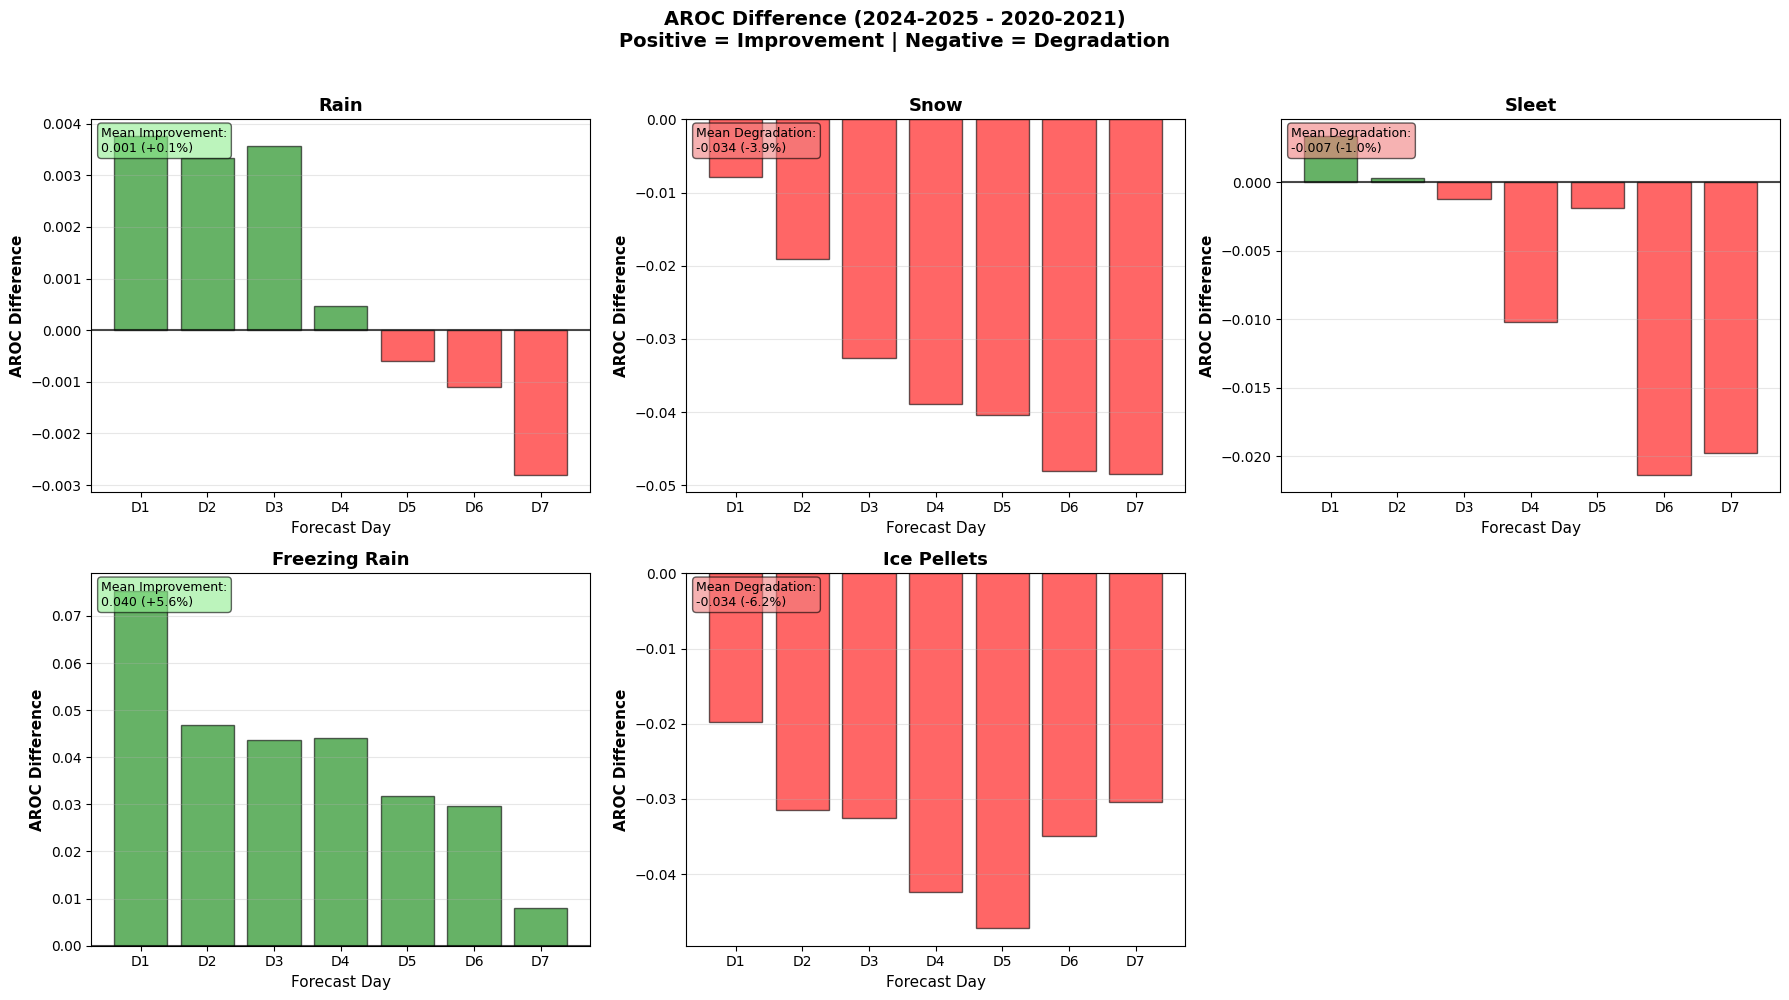

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import glob
from datetime import datetime
import os

#
# AROC COMPARISON - TWO DATASETS
# -------------------------------
#
# Compares AROC between two verification datasets
# Dataset 1: Solid lines
# Dataset 2: Dashed lines
#
########################################

# ===== CONFIGURATION =====
# Two datasets to compare
DATA_PATH_1 = "/ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2024_2025_49r1/"
DATA_PATH_2 = "/ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2020_2021/"

# Labels for datasets
LABEL_1 = "2024-2025"
LABEL_2 = "2020-2021"

OUTPUT_PATH = "./verification_results/comparison/"

if not os.path.exists(OUTPUT_PATH):
    os.makedirs(OUTPUT_PATH, exist_ok=True)

PRECIP_TYPES = ['rain', 'snow', 'sleet', 'freezrain', 'freezdrizzle', 'icepellets']

COLORS = {
    'rain': '#00CC00',
    'snow': '#0000FF',
    'sleet': '#00CCCC',
    'freezrain': '#FF0000',
    'freezdrizzle': '#FF1493',
    'icepellets': '#FF9900'
}

NICE_NAMES = {
    'rain': 'Rain',
    'snow': 'Snow',
    'sleet': 'Sleet',
    'freezrain': 'Freezing Rain',
    'freezdrizzle': 'Freezing Drizzle',
    'icepellets': 'Ice Pellets'
}

print("="*70)
print("AROC COMPARISON - TWO DATASETS")
print("="*70)
print(f"Dataset 1: {DATA_PATH_1}")
print(f"Dataset 2: {DATA_PATH_2}")
print(f"Output path: {OUTPUT_PATH}")
print()

# Day groupings
day_groups = {
    1: [0, 3, 6, 9, 12, 15, 18, 21],
    2: [24, 27, 30, 33, 36, 39, 42, 45],
    3: [48, 51, 54, 57, 60, 63, 66, 69],
    4: [72, 75, 78, 81, 84, 87, 90, 93],
    5: [96, 99, 102, 105, 108, 111, 114, 117],
    6: [120, 123, 126, 129, 132, 135, 138, 141],
    7: [144, 150, 156, 162, 168]
}

days = sorted(day_groups.keys())

# ===== FUNCTION TO LOAD AND PROCESS DATASET =====
def load_and_process_dataset(data_path, label):
    """Load data and calculate AROC metrics"""
    
    print(f"\nProcessing {label}...")
    print("-" * 70)
    
    # Load data
    files = sorted(glob.glob(data_path + "matched_pairs_*.parquet"))
    print(f"   Found {len(files)} files")
    
    if len(files) == 0:
        print(f"   ERROR: No files found!")
        return None
    
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    print(f"   Loaded {len(df):,} matched pairs")
    
    # Detect available precipitation types
    available_types = []
    for ptype in PRECIP_TYPES:
        obs_col = f'obs_{ptype}'
        prob_col = f'prob_{ptype}'
        if obs_col in df.columns and prob_col in df.columns:
            available_types.append(ptype)
        else:
            print(f"   ⚠️  Warning: '{ptype}' not found in dataset, skipping")
    
    print(f"   Available types: {', '.join([NICE_NAMES[p] for p in available_types])}")
    
    # Extract verification period
    start_date = df['forecast_date'].min()
    end_date = df['forecast_date'].max()
    start_date_str = f"{str(start_date)[:4]}-{str(start_date)[4:6]}-{str(start_date)[6:]}"
    end_date_str = f"{str(end_date)[:4]}-{str(end_date)[4:6]}-{str(end_date)[6:]}"
    period_str = f"{start_date_str} to {end_date_str}"
    print(f"   Period: {period_str}")
    
    # Calculate AROC for each day - only for available types
    aroc_results = {ptype: [] for ptype in available_types}
    n_samples = {ptype: [] for ptype in available_types}
    n_events = {ptype: [] for ptype in available_types}
    
    for day in days:
        steps_in_day = day_groups[day]
        df_day = df[df['forecast_step'].isin(steps_in_day)]
        
        for ptype in available_types:
            obs_col = f'obs_{ptype}'
            prob_col = f'prob_{ptype}'
            
            obs = df_day[obs_col].values
            prob = df_day[prob_col].values / 100.0  # Convert % to [0,1]
            
            # Remove NaN values
            valid_mask = ~np.isnan(prob)
            obs_valid = obs[valid_mask]
            prob_valid = prob[valid_mask]
            
            # Count events
            n_event = obs_valid.sum()
            n_valid = len(obs_valid)
            n_samples[ptype].append(n_valid)
            n_events[ptype].append(n_event)
            
            # Calculate AROC if we have both events and non-events
            if n_event > 0 and n_event < n_valid:
                try:
                    aroc = roc_auc_score(obs_valid, prob_valid)
                    aroc_results[ptype].append(aroc)
                except Exception:
                    aroc_results[ptype].append(np.nan)
            else:
                aroc_results[ptype].append(np.nan)
    
    print(f"   ✓ Completed")
    
    return {
        'aroc_results': aroc_results,
        'n_samples': n_samples,
        'n_events': n_events,
        'period_str': period_str,
        'label': label,
        'available_types': available_types
    }

# ===== LOAD BOTH DATASETS =====
print("\n" + "="*70)
print("LOADING DATASETS")
print("="*70)

dataset1 = load_and_process_dataset(DATA_PATH_1, LABEL_1)
dataset2 = load_and_process_dataset(DATA_PATH_2, LABEL_2)

if dataset1 is None or dataset2 is None:
    print("\nERROR: Could not load one or both datasets!")
    exit(1)

# Find common precipitation types
common_types = [p for p in dataset1['available_types'] if p in dataset2['available_types']]

if len(common_types) == 0:
    print("\nERROR: No common precipitation types between datasets!")
    exit(1)

print("\n" + "="*70)
print(f"Common precipitation types to compare: {', '.join([NICE_NAMES[p] for p in common_types])}")
print("="*70)

# ===== CREATE COMBINED AROC COMPARISON PLOT =====
print("\n" + "="*70)
print("CREATING COMPARISON PLOTS")
print("="*70)
print()

print("1. Creating combined AROC comparison plot...")

fig, ax = plt.subplots(figsize=(12, 8))

# Plot both datasets
for dataset, linestyle, linewidth, alpha in [(dataset1, '-', 2.5, 0.8), (dataset2, '--', 2.0, 0.7)]:
    
    aroc_results = dataset['aroc_results']
    
    for ptype in common_types:
        aroc_vals = np.array(aroc_results[ptype])
        
        # Count valid values
        n_valid = np.sum(~np.isnan(aroc_vals))
        
        if n_valid > 0:
            label = f"{NICE_NAMES[ptype]} ({dataset['label']})"
            ax.plot(days, aroc_vals, 
                    marker='o' if linestyle == '-' else 's',
                    linewidth=linewidth, 
                    markersize=8 if linestyle == '-' else 7,
                    linestyle=linestyle,
                    label=label,
                    color=COLORS[ptype],
                    alpha=alpha)

# Reference line at AROC = 0.5
ax.axhline(y=0.5, color='black', linestyle=':', linewidth=1.5, 
           label='No skill (0.5)', alpha=0.5)

# Formatting
ax.set_xlabel('Forecast Day', fontsize=14, fontweight='bold')
ax.set_ylabel('Area Under ROC Curve (AROC)', fontsize=14, fontweight='bold')
title_str = f'AROC Comparison - All Forecast Days\n'
title_str += f'Solid: {LABEL_1} | Dashed: {LABEL_2}'
ax.set_title(title_str, fontsize=14, fontweight='bold', pad=20)

ax.set_ylim([0.45, 1.0])
ax.set_xlim([0.5, len(days) + 0.5])
ax.set_xticks(days)
ax.set_xticklabels([f'D{d}' for d in days])

ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.set_axisbelow(True)

# Legend - two columns
ax.legend(loc='best', fontsize=9, framealpha=0.95, 
          edgecolor='black', fancybox=False, ncol=2)

ax.tick_params(axis='both', labelsize=11)

plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'aroc_comparison_combined.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}aroc_comparison_combined.png")
print()

# ===== CREATE INDIVIDUAL COMPARISON PLOTS =====
print("2. Creating individual comparison plots...")

# Determine subplot layout
n_types = len(common_types)
if n_types <= 3:
    nrows, ncols = 1, n_types
elif n_types <= 6:
    nrows, ncols = 2, 3
else:
    nrows, ncols = 3, 3

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
if n_types == 1:
    axes = [axes]
else:
    axes = axes.flatten() if n_types > 1 else [axes]

title_str = f'AROC Comparison by Precipitation Type\n'
title_str += f'Solid: {LABEL_1} | Dashed: {LABEL_2}'
fig.suptitle(title_str, fontsize=14, fontweight='bold', y=0.995)

for idx, ptype in enumerate(common_types):
    ax = axes[idx]
    
    # Plot both datasets
    aroc1 = np.array(dataset1['aroc_results'][ptype])
    aroc2 = np.array(dataset2['aroc_results'][ptype])
    
    ax.plot(days, aroc1, marker='o', linewidth=2.5, markersize=8,
            label=LABEL_1, color=COLORS[ptype], linestyle='-', alpha=0.8)
    ax.plot(days, aroc2, marker='s', linewidth=2.0, markersize=7,
            label=LABEL_2, color=COLORS[ptype], linestyle='--', alpha=0.7)
    
    # Reference line
    ax.axhline(y=0.5, color='black', linestyle=':', linewidth=1, alpha=0.4)
    
    # Formatting
    ax.set_xlabel('Forecast Day', fontsize=11)
    ax.set_ylabel('AROC', fontsize=11, fontweight='bold')
    ax.set_title(NICE_NAMES[ptype], fontsize=13, fontweight='bold', color=COLORS[ptype])
    ax.set_ylim([0.45, 1.0])
    ax.set_xlim([0.5, len(days) + 0.5])
    ax.set_xticks(days)
    ax.set_xticklabels([f'D{d}' for d in days])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=10)
    
    # Show mean AROC for both datasets
    mean_aroc1 = np.nanmean(aroc1)
    mean_aroc2 = np.nanmean(aroc2)
    
    textstr = f'{LABEL_1[:8]}: {mean_aroc1:.3f}\n{LABEL_2[:8]}: {mean_aroc2:.3f}'
    ax.text(0.98, 0.02, textstr, 
            transform=ax.transAxes, fontsize=9,
            verticalalignment='bottom', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Hide unused subplots
for idx in range(len(common_types), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(OUTPUT_PATH + 'aroc_comparison_individual.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}aroc_comparison_individual.png")
print()

# ===== CREATE IMPROVEMENT/DEGRADATION PLOT =====
print("3. Creating improvement/degradation plot...")

# Determine subplot layout
fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 5*nrows))
if n_types == 1:
    axes = [axes]
else:
    axes = axes.flatten() if n_types > 1 else [axes]

title_str = f'AROC Difference ({LABEL_1} - {LABEL_2})\n'
title_str += f'Positive = Improvement | Negative = Degradation'
fig.suptitle(title_str, fontsize=14, fontweight='bold', y=0.995)

for idx, ptype in enumerate(common_types):
    ax = axes[idx]
    
    # Calculate difference
    aroc1 = np.array(dataset1['aroc_results'][ptype])
    aroc2 = np.array(dataset2['aroc_results'][ptype])
    diff = aroc1 - aroc2
    
    # Plot as bar chart
    colors = ['green' if d > 0 else 'red' if d < 0 else 'gray' for d in diff]
    ax.bar(days, diff, color=colors, alpha=0.6, edgecolor='black', linewidth=1)
    
    # Zero line
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1.5, alpha=0.7)
    
    # Formatting
    ax.set_xlabel('Forecast Day', fontsize=11)
    ax.set_ylabel('AROC Difference', fontsize=11, fontweight='bold')
    ax.set_title(NICE_NAMES[ptype], fontsize=13, fontweight='bold')
    ax.set_xticks(days)
    ax.set_xticklabels([f'D{d}' for d in days])
    ax.grid(True, alpha=0.3, axis='y')
    
    # Show mean improvement
    mean_diff = np.nanmean(diff)
    improvement_pct = (mean_diff / np.nanmean(aroc2)) * 100 if np.nanmean(aroc2) > 0 else 0
    
    if mean_diff > 0:
        color_box = 'lightgreen'
        text = f'Mean Improvement:\n{mean_diff:.3f} ({improvement_pct:+.1f}%)'
    elif mean_diff < 0:
        color_box = 'lightcoral'
        text = f'Mean Degradation:\n{mean_diff:.3f} ({improvement_pct:+.1f}%)'
    else:
        color_box = 'lightyellow'
        text = 'No change'
    
    ax.text(0.02, 0.98, text, 
            transform=ax.transAxes, fontsize=9,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor=color_box, alpha=0.6))

# Hide unused subplots
for idx in range(len(common_types), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(OUTPUT_PATH + 'aroc_difference.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}aroc_difference.png")
print()

# ===== SUMMARY TABLE =====
print("="*70)
print("COMPARISON SUMMARY")
print("="*70)
print()
print(f"{'Type':<20} {LABEL_1 + ' AROC':<15} {LABEL_2 + ' AROC':<15} {'Difference':<15} {'Change %':<10}")
print("-"*80)

for ptype in common_types:
    aroc1 = np.nanmean(dataset1['aroc_results'][ptype])
    aroc2 = np.nanmean(dataset2['aroc_results'][ptype])
    diff = aroc1 - aroc2
    change_pct = (diff / aroc2) * 100 if aroc2 > 0 else 0
    
    symbol = "↑" if diff > 0 else "↓" if diff < 0 else "="
    
    print(f"{NICE_NAMES[ptype]:<20} {aroc1:>13.3f}  {aroc2:>13.3f}  {diff:>13.3f} {symbol}  {change_pct:>8.1f}%")

print()
print("Interpretation:")
print("  ↑ Positive difference = Improvement (higher AROC is better)")
print("  ↓ Negative difference = Degradation")
print()
print(f"All plots saved to: {OUTPUT_PATH}")